# Lista 2: Inteligência Artificial (UFAL)
## Questão 6: Sistema fuzzy de Mamdani para irrigação de hortaliças

**Dupla:**
- Bruno Gomes de Barros Filho, matrícula 21111360
- Antônio Rodrigo Lima de Andrade Tenório, matrícula 23210707

**Disciplina:** ECOM031: Inteligência Artificial
**Professor:** Evandro de Barros Costa
**Período:** 2026.2

---

### Enunciado (Q6)
> Desenvolva um sistema baseado em regras fuzzy, usando a ferramenta Scikit Fuzzy (ou uma outra de
> sua livre escolha), para uma aplicação de sua escolha. Sobre a solução a ser desenvolvida, apresente:
> Descrição do processo de modelagem, mostrando e discutindo as variáveis e os seus universos de
> discursos, as funções de pertinência utilizadas na etapa de fuzzificação, bem como a solução para
> etapa de defuzzificação), e discuta e mostre como é feita a inferência sobre o conhecimento.
> Obs.: Considere a metodologia e inferência de Mamdani.

A lógica do sistema está nos módulos `fuzzy_irrigacao.py` (modelo e inferência) e
`fuzzy_graficos.py` (figuras). Este notebook importa os dois e percorre o sistema etapa por etapa.
O relatório completo está no `README.md` desta pasta.

## 1. Aplicação escolhida

Escolhemos decidir quanto tempo ligar a irrigação por gotejamento de uma horta no Agreste alagoano
(região de Arapiraca, onde a olericultura irrigada é comum). Uma vez por dia o controlador lê três
grandezas e devolve o tempo de funcionamento da bomba:

| Papel | Variável | Origem da medida |
|---|---|---|
| entrada | umidade do solo, em % da água disponível | sensor capacitivo ou tensiômetro |
| entrada | temperatura do ar, em °C | estação meteorológica simples |
| entrada | probabilidade de chuva prevista para as próximas 24 h, em % | previsão do tempo (INMET ou aplicativo) |
| saída | tempo de irrigação, em minutos | acionamento da bomba |

O problema combina bem com lógica fuzzy. O conhecimento de quem maneja a horta é verbal
("solo seco e dia muito quente pede irrigação longa", "se vai chover bastante, não precisa irrigar")
e as fronteiras entre as categorias são graduais: 34 % de água disponível não é muito diferente de 36 %.
Um controlador de limiar fixo (liga abaixo de X %) ignora a temperatura e a previsão e muda de
comportamento de forma brusca no limiar.

## 2. Imports

In [1]:
import warnings

import numpy as np
import pandas as pd
import skfuzzy as fuzz
from IPython.display import display
from skfuzzy import control as ctrl

import fuzzy_irrigacao as fi
import fuzzy_graficos as fg

# O skfuzzy 0.5 chama np.maximum com 3 argumentos posicionais, o que gera um
# DeprecationWarning no NumPy 2.x. O resultado está correto; só silenciamos o aviso.
warnings.filterwarnings("ignore", category=DeprecationWarning, module="skfuzzy")
pd.set_option("display.precision", 3)
print("scikit-fuzzy", fuzz.__version__, "| numpy", np.__version__)

scikit-fuzzy 0.5.0 | numpy 2.5.4


## 3. Modelagem: variáveis e universos de discurso

Cada universo cobre a faixa física que a variável pode assumir na aplicação:

* **Umidade do solo (0 a 100 %)**: medida como fração da água disponível, em que 0 % é o ponto de
  murcha permanente e 100 % é a capacidade de campo. Usar essa escala, em vez da umidade volumétrica
  bruta, deixa o sistema independente do tipo de solo; a calibração do sensor faz a conversão.
* **Temperatura do ar (15 a 40 °C)**: no Agreste alagoano as mínimas raramente ficam abaixo de 15 °C e
  as máximas raramente passam de 40 °C, então o intervalo cobre o ano todo com folga.
* **Probabilidade de chuva (0 a 100 %)**: é uma probabilidade, o universo é o intervalo inteiro.
* **Tempo de irrigação (0 a 60 min)**: para gotejamento em canteiros de hortaliças, uma hora por dia é
  um teto razoável; acima disso o excesso de água começa a drenar abaixo das raízes.

As entradas são discretizadas com passo 0,5 (umidade e chuva) e 0,1 (temperatura e tempo). O passo da
saída importa para a defuzzificação: com 601 pontos a integral numérica do centroide fica precisa.

In [2]:
pd.DataFrame([
    {"variável": fi.NOMES[v], "mín": fi.UNIVERSOS[v][0], "máx": fi.UNIVERSOS[v][-1],
     "pontos": fi.UNIVERSOS[v].size, "termos": ", ".join(fi.TERMOS[v])}
    for v in (*fi.ENTRADAS, "tempo")
])

,variável,mín,máx,pontos,termos
0,Umidade do solo (% da água disponível),0.0,100.0,201,"seca, adequada, úmida"
1,Temperatura do ar (°C),15.0,40.0,251,"amena, quente, muito quente"
2,Probabilidade de chuva prevista (%),0.0,100.0,201,"baixa, média, alta"
3,Tempo de irrigação (min),0.0,60.0,601,"nenhum, curto, médio, longo, muito longo"


## 4. Fuzzificação: funções de pertinência

A escolha do formato de cada função seguiu o significado de cada variável:

* **Umidade do solo (trapezoidal nas pontas, triangular no meio).** O manejo de irrigação trabalha com
  limiares: a FAO-56 (Allen et al., 1998) recomenda repor a água quando o esgotamento passa de uma
  fração *p* da água disponível, que para a maioria das hortaliças fica entre 0,3 e 0,5. Abaixo de 20 %
  o solo está seco de qualquer ponto de vista, e acima de 80 % está úmido; por isso os ombros
  trapezoidais têm patamar com pertinência 1. O termo `adequada` é triangular com pico em 50 %, que
  é o meio da faixa de esgotamento permitido.
* **Temperatura (gaussiana).** O efeito do calor sobre a evapotranspiração cresce de forma suave, sem
  quebras. A gaussiana representa isso e ainda mostra um tipo diferente de função. O custo é que ela
  nunca chega a zero: todo termo de temperatura tem pertinência positiva em qualquer ponto, e isso faz
  algumas regras dispararem com força muito pequena (aparece na inferência abaixo).
* **Chuva prevista (trapezoidal e triangular).** Previsões abaixo de 20 % são tratadas como "não vai
  chover" e acima de 80 % como "vai chover", com uma faixa de dúvida no meio.
* **Tempo de irrigação (5 triângulos).** Picos em 0, 15, 30, 45 e 60 min, igualmente espaçados, com
  cada triângulo terminando no pico do vizinho. Em cada ponto as pertinências somam 1 (partição de
  Ruspini), o que deixa a saída mais fácil de interpretar.

In [3]:
pd.DataFrame([
    {"variável": v, "termo": t, "tipo": tipo, "parâmetros": p}
    for v in (*fi.ENTRADAS, "tempo") for t, (tipo, p) in fi.TERMOS[v].items()
])

,variável,termo,tipo,parâmetros
0,umidade,seca,trap,"[0, 0, 20, 45]"
1,umidade,adequada,tri,"[25, 50, 75]"
2,umidade,úmida,trap,"[55, 80, 100, 100]"
3,temperatura,amena,gauss,"[15, 5]"
4,temperatura,quente,gauss,"[27, 4]"
5,temperatura,muito quente,gauss,"[40, 5]"
6,chuva,baixa,trap,"[0, 0, 20, 40]"
7,chuva,média,tri,"[20, 50, 80]"
8,chuva,alta,trap,"[60, 80, 100, 100]"
9,tempo,nenhum,tri,"[0, 0, 15]"


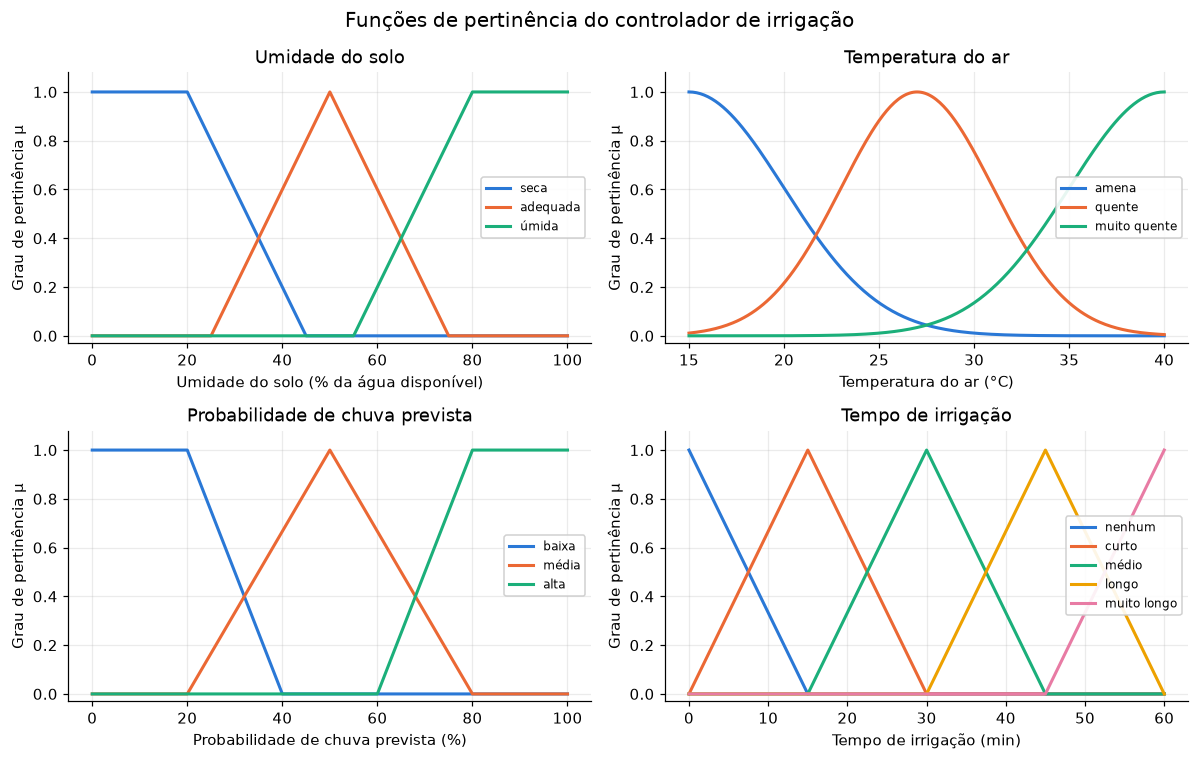

In [4]:
fig = fg.figura_pertinencias()
fg.salvar(fig, "q06_pertinencias");

## 5. Base de conhecimento: as 27 regras

Com 3 termos em cada entrada há 3 × 3 × 3 = 27 combinações, e escrevemos uma regra para cada uma.
Assim nenhuma região do espaço de entradas fica sem resposta. Todas as regras têm a forma

`SE umidade é A E temperatura é B E chuva é C ENTÃO tempo é D`.

O raciocínio que gerou a tabela:

1. A umidade do solo é o fator principal: solo seco pede irrigação longa, solo úmido não pede nenhuma.
2. A temperatura aumenta a demanda: subir de `amena` para `muito quente` pode subir a saída um nível.
3. A chuva prevista reduz a necessidade: cada nível de chuva pode descer a saída um nível.
4. Com solo `úmido` a saída é sempre `nenhum`, porque irrigar um solo perto da capacidade de campo só
   faz a água drenar e levar nutrientes junto.

As três matrizes abaixo mostram a base completa. As linhas são a umidade, as colunas a temperatura, e
cada painel corresponde a um nível de chuva.

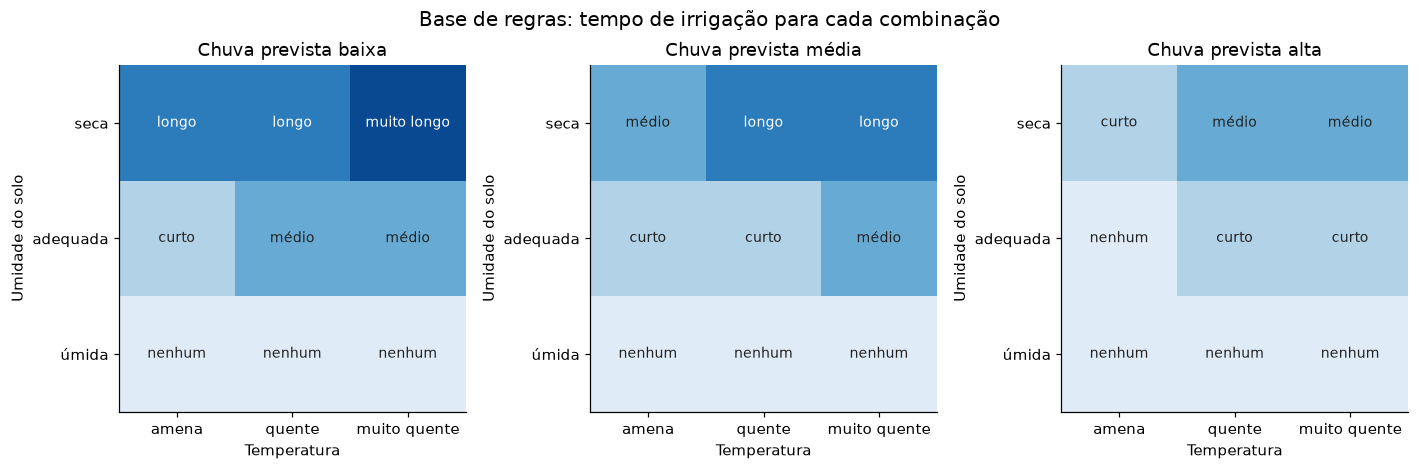

In [5]:
fig = fg.figura_matriz_regras()
fg.salvar(fig, "q06_matriz_regras");

In [6]:
tabela_regras = pd.DataFrame(
    [vars(r) for r in fi.REGRAS], index=[f"R{i}" for i in range(1, len(fi.REGRAS) + 1)]
)
print(len(tabela_regras), "regras; distribuição dos consequentes:")
print(tabela_regras["tempo"].value_counts().reindex(fi.TERMOS["tempo"]).to_string())
tabela_regras

27 regras; distribuição dos consequentes:
tempo
nenhum         10
curto           6
médio           6
longo           4
muito longo     1


,umidade,temperatura,chuva,tempo
R1,seca,amena,baixa,longo
R2,seca,amena,média,médio
R3,seca,amena,alta,curto
R4,seca,quente,baixa,longo
R5,seca,quente,média,longo
R6,seca,quente,alta,médio
R7,seca,muito quente,baixa,muito longo
R8,seca,muito quente,média,longo
R9,seca,muito quente,alta,médio
R10,adequada,amena,baixa,curto


O teste `test_regras_monotonas_na_tabela` confere as três propriedades acima em todas as regras: mais
umidade ou mais chuva nunca aumenta o nível de saída, e mais calor nunca o reduz.

## 6. Inferência de Mamdani passo a passo

Os operadores são os da formulação clássica de Mamdani:

| Etapa | Operação | Operador |
|---|---|---|
| conjunção dos antecedentes (E) | força de disparo da regra | mínimo |
| disjunção (OU, não usada nas regras) | | máximo |
| implicação | corta o conjunto consequente na altura da força | mínimo |
| agregação | une as saídas de todas as regras | máximo |
| defuzzificação | transforma o conjunto agregado em um número | centroide |

Caso concreto: uma tarde de verão com o solo já secando, **umidade 38 %, temperatura 32 °C e chuva
prevista de 25 %**.

In [7]:
caso = {"umidade": 38, "temperatura": 32, "chuva": 25}
resultado = fi.inferir(**caso)

### 6.1 Etapa 1: fuzzificação

Cada valor numérico vira um conjunto de graus de pertinência, um para cada termo da variável.

,variável,termo,grau μ
0,umidade,seca,0.280
1,umidade,adequada,0.520
2,umidade,úmida,0.000
3,temperatura,amena,0.003
4,temperatura,quente,0.458
5,temperatura,muito quente,0.278
6,chuva,baixa,0.750
7,chuva,média,0.167
8,chuva,alta,0.000


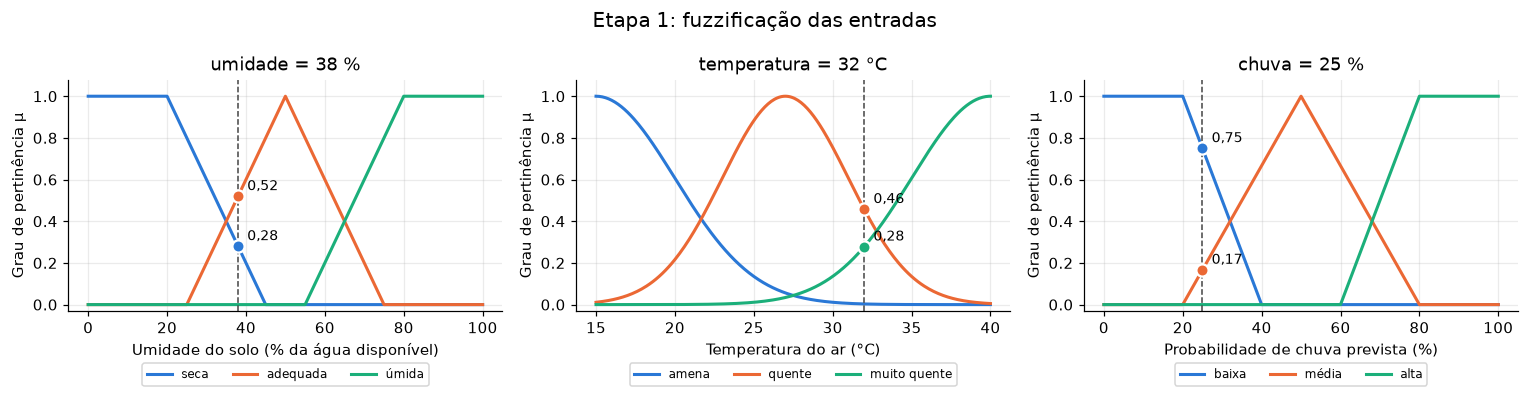

In [8]:
display(pd.DataFrame([{"variável": v, "termo": t, "grau μ": g}
                      for v, termos in resultado.graus.items() for t, g in termos.items()]))
fig = fg.figura_fuzzificacao(caso)
fg.salvar(fig, "q06_fuzzificacao");

A umidade de 38 % pertence ao mesmo tempo a `seca` (0,28) e a `adequada` (0,52). Os 25 % de chuva são
quase todos `baixa` (0,75). Na temperatura, 32 °C é `quente` com grau 0,46 e `muito quente` com 0,28;
o termo `amena` ainda tem um grau minúsculo por causa da cauda da gaussiana.

### 6.2 Etapa 2: força de disparo de cada regra (E = mínimo)

A força de cada regra é o menor dos três graus dos seus antecedentes. A tabela lista as 27 regras,
da mais forte para a mais fraca.

In [9]:
disparo = tabela_regras.copy()
for var in fi.ENTRADAS:
    disparo[f"μ {var}"] = [resultado.graus[var][t] for t in disparo[var]]
disparo["força (min)"] = resultado.forcas
disparo = disparo.sort_values("força (min)", ascending=False)
print("regras com força > 0:", int((resultado.forcas > 0).sum()),
      "| com força > 0,01:", int((resultado.forcas > 0.01).sum()))
disparo

regras com força > 0: 12 | com força > 0,01: 8


,umidade,temperatura,chuva,tempo,μ umidade,μ temperatura,μ chuva,força (min)
R13,adequada,quente,baixa,médio,0.52,0.458,0.750,0.458
R4,seca,quente,baixa,longo,0.28,0.458,0.750,0.280
R7,seca,muito quente,baixa,muito longo,0.28,0.278,0.750,0.278
R16,adequada,muito quente,baixa,médio,0.52,0.278,0.750,0.278
R17,adequada,muito quente,média,médio,0.52,0.278,0.167,0.167
R8,seca,muito quente,média,longo,0.28,0.278,0.167,0.167
R5,seca,quente,média,longo,0.28,0.458,0.167,0.167
R14,adequada,quente,média,curto,0.52,0.458,0.167,0.167
R11,adequada,amena,média,curto,0.52,0.003,0.167,0.003
R1,seca,amena,baixa,longo,0.28,0.003,0.750,0.003


Todas as regras que envolvem chuva `alta` ou umidade `úmida` têm força zero, porque esses termos têm
grau zero no caso. As regras com temperatura `amena` disparam com força 0,003: é o efeito do suporte
infinito da gaussiana. Essa contribuição não muda o resultado de forma perceptível, mas mostra uma
consequência prática da escolha do formato.

### 6.3 Etapa 3: implicação (mínimo) e combinação das regras de mesmo consequente

Na implicação de Mamdani o conjunto consequente de cada regra é cortado na altura da sua força. Como
várias regras apontam para o mesmo termo de saída e a agregação é por máximo, o corte efetivo de cada
termo é a maior força entre as regras daquele termo.

In [10]:
ativacao = (disparo.groupby("tempo")["força (min)"].agg(["max", "count"])
            .reindex(fi.TERMOS["tempo"])
            .rename(columns={"max": "corte (max das forças)", "count": "nº de regras"}))
regra_vencedora = disparo.reset_index().groupby("tempo").first()["index"]
ativacao["regra que define o corte"] = regra_vencedora.where(ativacao["corte (max das forças)"] > 0, "")
assert np.allclose(ativacao["corte (max das forças)"], list(resultado.ativacao.values()))
ativacao

,corte (max das forças),nº de regras,regra que define o corte
tempo,,,
nenhum,0.000,10,
curto,0.167,6,R14
médio,0.458,6,R13
longo,0.280,4,R4
muito longo,0.278,1,R7


### 6.4 Etapa 4: agregação (máximo) e etapa 5: defuzzificação

O conjunto agregado é a união (máximo ponto a ponto) dos consequentes cortados. A figura da esquerda
mostra os cortes e a da direita o conjunto agregado, com a posição de cada método de defuzzificação.

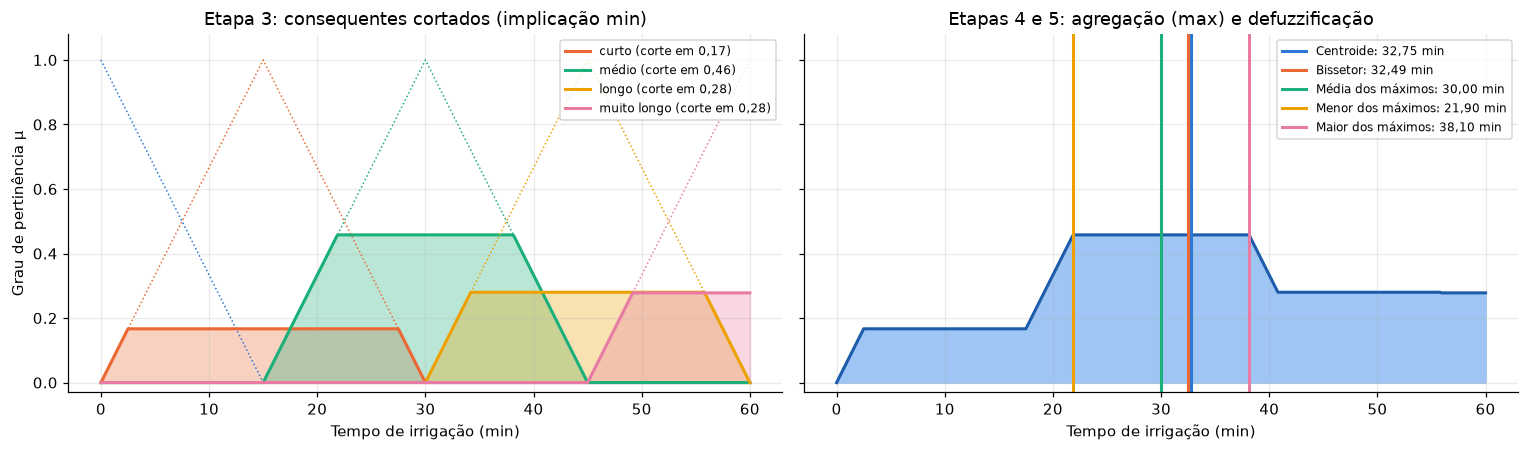

In [11]:
fig = fg.figura_agregacao(resultado)
fg.salvar(fig, "q06_agregacao_defuzzificacao");

### 6.5 Centroide calculado à mão e conferido com o skfuzzy

O centroide é o centro de gravidade da área sob o conjunto agregado:

$$ z^* = \frac{\int z\,\mu_{agr}(z)\,dz}{\int \mu_{agr}(z)\,dz} $$

Calculamos de três formas: pela integral numérica (regra do trapézio), pela soma discreta que aparece
nos livros ($\sum z_i \mu_i / \sum \mu_i$), pela função `fuzz.defuzz` e pelo sistema completo montado
com `skfuzzy.control`.

In [12]:
z, mu = fi.UNIVERSOS["tempo"], resultado.agregado
numerador, area = np.trapezoid(z * mu, z), np.trapezoid(mu, z)
print(f"∫ z·μ(z) dz = {numerador:.4f}")
print(f"∫ μ(z) dz   = {area:.4f}")
c_integral = fi.centroide_manual(z, mu)
c_soma = (z * mu).sum() / mu.sum()
c_defuzz = fi.defuzzificar(mu, "centroid")
sistema = fi.criar_sistema_skfuzzy()
c_ctrl = fi.tempo_irrigacao_skfuzzy(sistema, **caso)
pd.Series({
    "integral (trapézio, numpy)": c_integral,
    "soma discreta Σzμ/Σμ": c_soma,
    "fuzz.defuzz(centroid)": c_defuzz,
    "skfuzzy.control (sistema completo)": c_ctrl,
}, name="centroide (min)").to_frame()

∫ z·μ(z) dz = 585.2610
∫ μ(z) dz   = 17.8705


,centroide (min)
"integral (trapézio, numpy)",32.750
soma discreta Σzμ/Σμ,32.771
fuzz.defuzz(centroid),32.750
skfuzzy.control (sistema completo),32.750


A integral numérica, o `fuzz.defuzz` e o `skfuzzy.control` dão o mesmo valor. O `skfuzzy.control`
ainda insere no universo os pontos exatos onde cada linha de corte cruza a função de pertinência, e
mesmo assim a diferença para a grade fixa de 0,1 min só aparece depois da terceira casa decimal.
A soma discreta fica 0,02 min acima. Ela dá peso cheio aos dois pontos extremos do universo, e aqui o
extremo z = 60 min tem pertinência 0,278 (corte de `muito longo`), enquanto a regra do trapézio dá
peso pela metade às pontas. Com a grade fina a diferença é pequena, mas ela mostra que a fórmula
do livro é uma aproximação da integral.

Para conferir que as duas implementações são o mesmo sistema, e não apenas coincidem nesse caso,
comparamos as saídas em 300 entradas sorteadas no espaço todo.

In [13]:
rng = np.random.default_rng(2026)
amostras = np.column_stack([rng.uniform(0, 100, 300), rng.uniform(15, 40, 300), rng.uniform(0, 100, 300)])
dif = [abs(fi.tempo_irrigacao(*a) - fi.tempo_irrigacao_skfuzzy(sistema, *a)) for a in amostras]
print(f"maior diferença entre a implementação manual e o skfuzzy.control: {max(dif):.5f} min")

maior diferença entre a implementação manual e o skfuzzy.control: 0.00047 min


## 7. Comparação dos métodos de defuzzificação

O skfuzzy oferece cinco métodos. No caso concreto:

In [14]:
pd.Series({nome: fi.defuzzificar(resultado.agregado, m) for m, nome in fg.METODOS.items()},
          name="tempo (min)").to_frame()

,tempo (min)
Centroide,32.75
Bissetor,32.49
Média dos máximos,30.00
Menor dos máximos,21.90
Maior dos máximos,38.10


O centroide e o bissetor usam a forma inteira do conjunto agregado. Os três métodos de máximo olham
só para o patamar mais alto: aqui o termo `médio` tem o maior corte, então eles devolvem valores dentro
do patamar de `médio`, ignorando que `longo` e `muito longo` também foram ativados. Para ver o efeito
na operação, variamos a umidade de 0 a 100 % com temperatura e chuva do caso base.

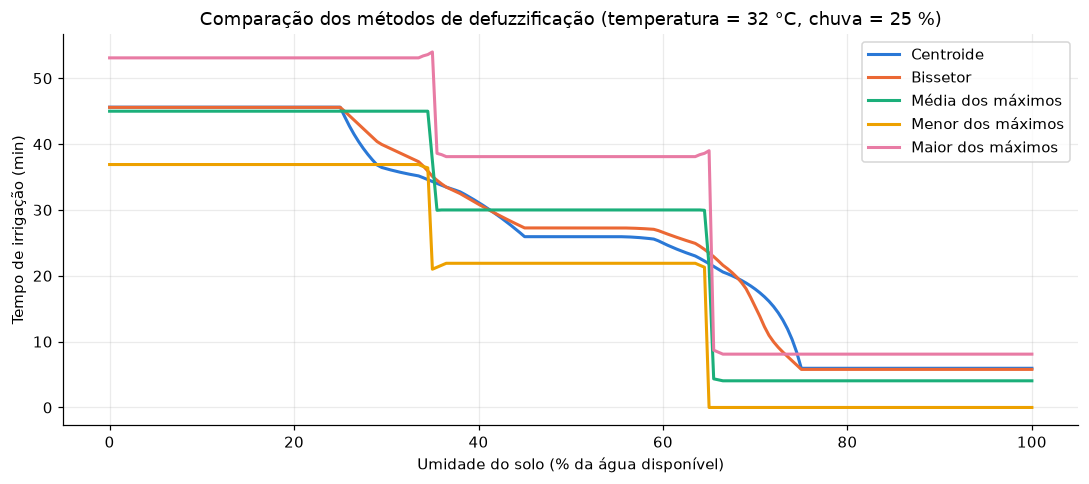

In [15]:
fig = fg.figura_metodos_defuzz(caso, "umidade")
fg.salvar(fig, "q06_metodos_defuzzificacao");

In [16]:
xs = np.linspace(0, 100, 201)
agregados = [fi.inferir(u, caso["temperatura"], caso["chuva"]).agregado for u in xs]
linhas = []
for m, nome in fg.METODOS.items():
    ys = np.array([fi.defuzzificar(a, m) for a in agregados])
    linhas.append({"método": nome, "maior salto entre passos de 0,5 % (min)": np.abs(np.diff(ys)).max(),
                   "valores distintos": len(np.unique(ys.round(2)))})
pd.DataFrame(linhas)

,método,"maior salto entre passos de 0,5 % (min)",valores distintos
0,Centroide,2.432,80
1,Bissetor,1.582,80
2,Média dos máximos,17.119,8
3,Menor dos máximos,21.300,8
4,Maior dos máximos,30.300,11


Os métodos de máximo produzem uma saída em degraus, com saltos de vários minutos quando o termo
dominante muda. Para um controlador isso é ruim: uma variação mínima no sensor muda bastante a ação.
O centroide varia de forma contínua e por isso é o método adotado. O maior passo dele na varredura
(cerca de 2,4 min entre 74,5 % e 75 % de umidade) acontece quando o termo `adequada` chega a zero e
só o conjunto `nenhum` continua ativo; é uma região íngreme da curva, sem salto. O bissetor fica
próximo do centroide, com custo parecido.

## 8. Superfície de controle e mapas de calor

A superfície mostra o tempo de irrigação em função da umidade e da temperatura, com chuva prevista
baixa (10 %). Os mapas de calor cobrem os três pares de entradas.

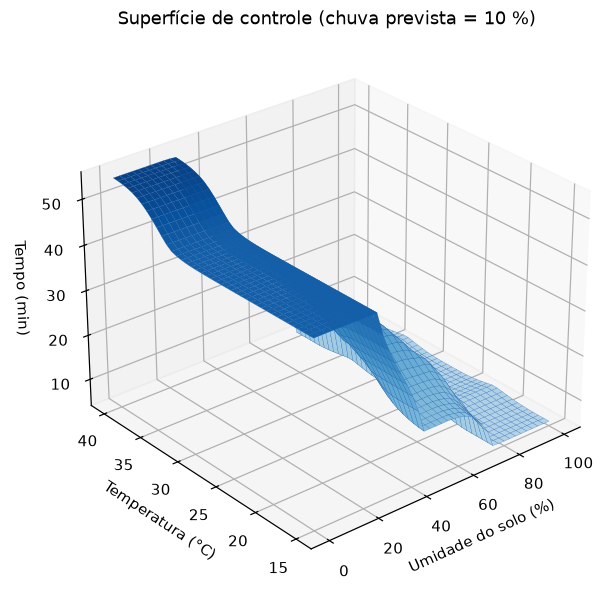

In [17]:
fig = fg.figura_superficie_3d(chuva=10)
fg.salvar(fig, "q06_superficie_3d");

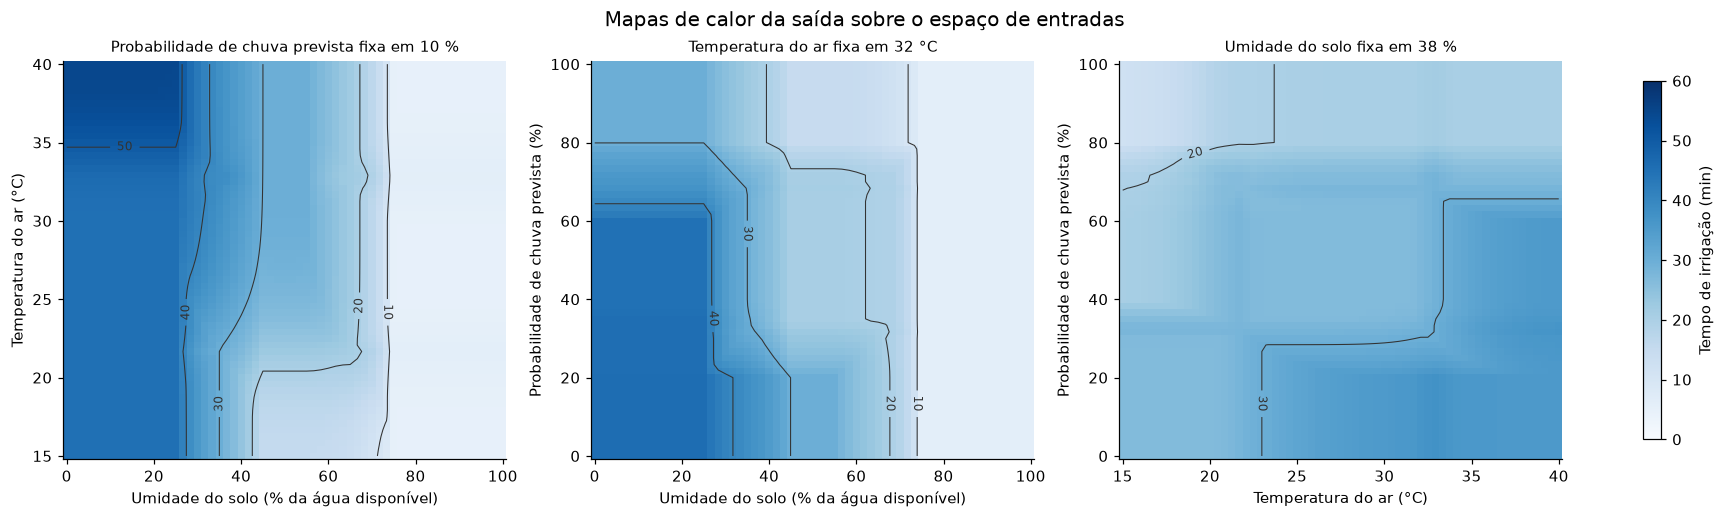

In [18]:
fig = fg.figura_mapas_calor([
    ("umidade", "temperatura", {"chuva": 10}),
    ("umidade", "chuva", {"temperatura": 32}),
    ("temperatura", "chuva", {"umidade": 38}),
])
fg.salvar(fig, "q06_mapas_calor");

Pontos que a superfície deixa visíveis:

* abaixo de 20 % de umidade a saída não depende da umidade, porque `seca` está no patamar do trapézio;
  o mesmo acontece acima de 80 % com `úmida`;
* o mínimo da saída não é 0 min. Quando só o conjunto `nenhum` está ativo e com corte 1, o centroide
  do triângulo [0, 0, 15] é 5 min. Esse é um efeito conhecido do centroide, que nunca alcança as pontas
  do universo. Se o corte for menor que 1, o triângulo cortado vira um trapézio, a área se desloca para
  a direita e o resultado sobe um pouco (5,95 min com corte 0,458, por exemplo);
* a temperatura pesa mais quando o solo está seco ou adequado. Com solo úmido a tabela manda `nenhum`
  em qualquer temperatura, mas a superfície ainda ondula de leve nessa região: com 90 % de umidade e
  10 % de chuva a saída vai de 5,0 a 6,3 min conforme a temperatura. A seção 9 explica a causa.

## 9. Análise de sensibilidade

Primeiro variamos uma entrada por vez em todo o universo, mantendo as outras no caso base.

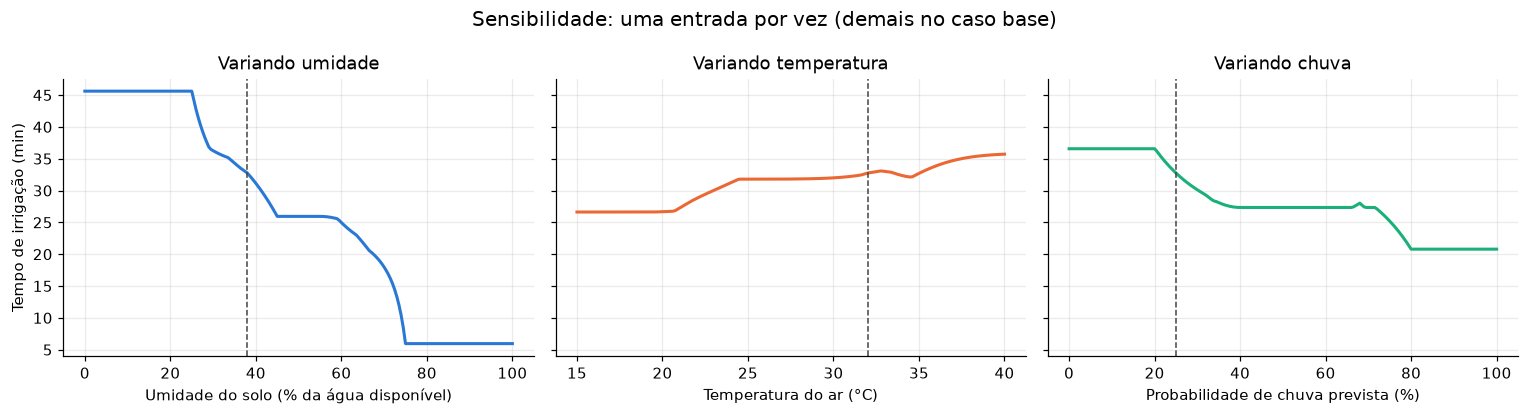

In [19]:
fig = fg.figura_sensibilidade(caso)
fg.salvar(fig, "q06_sensibilidade");

In [20]:
linhas = []
for var in fi.ENTRADAS:
    xs = np.linspace(fi.UNIVERSOS[var][0], fi.UNIVERSOS[var][-1], 201)
    ys = np.array([fi.tempo_irrigacao(**{**caso, var: x}) for x in xs])
    h = 0.5
    derivada = (fi.tempo_irrigacao(**{**caso, var: caso[var] + h})
                - fi.tempo_irrigacao(**{**caso, var: caso[var] - h})) / (2 * h)
    linhas.append({"entrada": var, "saída mín (min)": ys.min(), "saída máx (min)": ys.max(),
                   "amplitude (min)": ys.max() - ys.min(),
                   "derivada no caso base": derivada, "unidade": f"min/{fi.UNIDADES[var]}"})
pd.DataFrame(linhas)

,entrada,saída mín (min),saída máx (min),amplitude (min),derivada no caso base,unidade
0,umidade,5.953,45.611,39.658,-0.628,min/%
1,temperatura,26.622,35.712,9.090,0.572,min/°C
2,chuva,20.793,36.566,15.774,-0.637,min/%


Em torno do caso base a umidade é a entrada com maior amplitude, como pede o raciocínio da seção 5.
A chuva vem em seguida e a temperatura tem a menor amplitude.

A análise de uma entrada por vez depende do ponto base. Para uma visão global, varremos uma grade
26 × 26 × 26 do espaço inteiro e medimos (a) a amplitude média da saída quando só uma entrada varia e
(b) quantas vezes a saída anda no sentido contrário ao esperado entre dois pontos vizinhos da grade.

In [21]:
U = np.linspace(0, 100, 26); T = np.linspace(15, 40, 26); C = np.linspace(0, 100, 26)
SINAL = {"umidade": -1, "temperatura": 1, "chuva": -1}


def varrer(regras):
    return np.array([[[fi.tempo_irrigacao(u, t, c, regras=regras) for c in C] for t in T] for u in U])


def resumo_monotonia(grade):
    linhas = []
    for eixo, var in enumerate(fi.ENTRADAS):
        passos = SINAL[var] * np.diff(grade, axis=eixo)
        linhas.append({
            "entrada": var, "sentido esperado": "diminui" if SINAL[var] < 0 else "aumenta",
            "amplitude média (min)": np.ptp(grade, axis=eixo).mean(),
            "inversões > 0,1 min": f"{(passos < -0.1).sum()} de {passos.size}",
            "maior inversão (min)": max(0.0, -passos.min()),
        })
    return pd.DataFrame(linhas)


grade = varrer(fi.REGRAS)
resumo_monotonia(grade)

,entrada,sentido esperado,amplitude média (min),"inversões > 0,1 min",maior inversão (min)
0,umidade,diminui,32.341,124 de 16900,0.982
1,temperatura,aumenta,8.590,1600 de 16900,1.286
2,chuva,diminui,11.527,1421 de 16900,1.889


Na média sobre o espaço inteiro a ordem de influência se mantém: umidade, depois chuva, depois
temperatura.

A segunda medida mostra uma propriedade do Mamdani com centroide que costuma passar despercebida. A
base de regras é monótona (o teste automatizado confere isso regra a regra), mas a saída
defuzzificada tem inversões locais. Para entender de onde elas vêm, olhamos a pior inversão no eixo
da chuva.

In [22]:
passos = SINAL["chuva"] * np.diff(grade, axis=2)
i, j, k = np.unravel_index(np.argmin(passos), passos.shape)
pontos = [(U[i], T[j], C[k]), (U[i], T[j], C[k + 1])]
pd.DataFrame([{"umidade": u, "temperatura": t, "chuva": c,
               **{f"μ umidade {n}": g for n, g in fi.fuzzificar(u, t, c)["umidade"].items()},
               **{f"μ chuva {n}": g for n, g in fi.fuzzificar(u, t, c)["chuva"].items()},
               **{f"corte {n}": a for n, a in fi.inferir(u, t, c).ativacao.items()},
               "tempo (min)": fi.tempo_irrigacao(u, t, c)}
              for u, t, c in pontos]).T

,0,1
umidade,72.000,72.000
temperatura,40.000,40.000
chuva,28.000,32.000
μ umidade seca,0.000,0.000
μ umidade adequada,0.120,0.120
μ umidade úmida,0.680,0.680
μ chuva baixa,0.600,0.400
μ chuva média,0.267,0.400
μ chuva alta,0.000,0.000
corte nenhum,0.600,0.400


Com 72 % de umidade o solo é `úmido` com grau 0,68 e `adequado` com grau 0,12. As nove regras de solo
úmido mandam não irrigar, qualquer que seja a chuva. Só que cada uma delas também exige um termo de
chuva, e o corte de `nenhum` vira min(0,68; maior grau de chuva). Entre 28 % e 32 % a chuva está saindo
de `baixa` e entrando em `média`, e o maior dos dois graus cai de 0,6 para 0,4. O corte de `nenhum`
cai junto, o corte de `médio` (vindo do solo adequado) fica onde estava, e o centroide sobe: mais
chuva prevista resultou em mais irrigação. Na temperatura o efeito aparece com mais frequência porque
as gaussianas vizinhas se cruzam em graus ainda mais baixos, entre 0,35 e 0,41.

A causa está na forma como a base foi escrita. As nove regras de solo úmido carregam antecedentes
irrelevantes (temperatura e chuva), e cada antecedente extra pode enfraquecer a regra nos vales entre
termos vizinhos. Para testar essa explicação, a variante `REGRAS_COMPACTAS` troca as nove regras por
uma só, `SE umidade é úmida ENTÃO tempo é nenhum`, e mantém as outras 18.

In [23]:
grade_compacta = varrer(fi.REGRAS_COMPACTAS)
comparacao = pd.concat({"27 regras": resumo_monotonia(grade).set_index("entrada"),
                        "19 regras (compacta)": resumo_monotonia(grade_compacta).set_index("entrada")},
                       axis=1)
print(f"maior diferença de saída entre as duas bases: {np.abs(grade - grade_compacta).max():.2f} min")
comparacao.loc[:, (slice(None), ["inversões > 0,1 min", "maior inversão (min)"])]

maior diferença de saída entre as duas bases: 2.70 min


27 regras                      19 regras (compacta)  \
            inversões > 0,1 min maior inversão (min)  inversões > 0,1 min   
entrada                                                                     
umidade            124 de 16900                0.982         123 de 16900   
temperatura       1600 de 16900                1.286         405 de 16900   
chuva             1421 de 16900                1.889         416 de 16900   

                                  
            maior inversão (min)  
entrada                           
umidade                    0.982  
temperatura                1.240  
chuva                      1.768

A base compacta reduz bastante o número de inversões nos eixos de temperatura e chuva, mas não as
elimina, porque o mesmo vale entre termos vizinhos continua presente nas regras de solo seco e
adequado. Ela também elimina a ondulação na região de solo úmido: com 90 % de umidade e 10 % de chuva
a saída fica em 5,0 min para qualquer temperatura. A maior diferença entre as duas bases (2,7 min)
aparece na transição entre `adequada` e `úmida`, em 72 % de umidade, 33 °C e sem chuva. As inversões que sobram ficam abaixo de 2 min, o que não tem efeito prático numa irrigação
diária, e o teste `test_monotonia_aproximada_em_varreduras` usa esse limite. Mantivemos a base de 27
regras como sistema principal porque ela corresponde à matriz da seção 5 e é mais fácil de conferir
item a item. A versão compacta fica registrada como melhoria possível.

## 10. Casos de borda

### 10.1 Valores nos limites do universo

In [24]:
cantos = [(u, t, c) for u in (0, 100) for t in (15, 40) for c in (0, 100)]
pd.DataFrame([{"umidade": u, "temperatura": t, "chuva": c,
               "tempo (min)": fi.tempo_irrigacao(u, t, c),
               "skfuzzy.control": fi.tempo_irrigacao_skfuzzy(sistema, u, t, c)}
              for u, t, c in cantos])

,umidade,temperatura,chuva,tempo (min),skfuzzy.control
0,0,15,0,45.000,45.000
1,0,15,100,15.246,15.246
2,0,40,0,54.824,54.824
3,0,40,100,30.000,30.000
4,100,15,0,5.000,5.000
5,100,15,100,5.000,5.000
6,100,40,0,5.000,5.000
7,100,40,100,5.000,5.000


O maior tempo possível sai com solo seco, 40 °C e sem chuva. Ele não chega a 60 min pelo mesmo motivo
do piso de 5 min: o centroide de um conjunto que inclui `longo` e `muito longo` fica sempre abaixo
do pico de `muito longo`.

### 10.2 Entradas fora do universo

Uma leitura fora da faixa (sensor com defeito ou fim de escala) é saturada no limite do universo. É o
comportamento padrão do skfuzzy (`clip_to_bounds=True`) e foi reproduzido na versão manual.

In [25]:
for leitura in [(-10, 55, -5), (120, 10, 150)]:
    limite = tuple(np.clip(v, fi.UNIVERSOS[k][0], fi.UNIVERSOS[k][-1]) for k, v in zip(fi.ENTRADAS, leitura))
    print(f"leitura {leitura} -> tratada como {tuple(float(v) for v in limite)}: "
          f"manual {fi.tempo_irrigacao(*leitura):.2f} min, skfuzzy {fi.tempo_irrigacao_skfuzzy(sistema, *leitura):.2f} min")

leitura (-10, 55, -5) -> tratada como (0.0, 40.0, 0.0): manual 54.82 min, skfuzzy 54.82 min
leitura (120, 10, 150) -> tratada como (100.0, 15.0, 100.0): manual 5.00 min, skfuzzy 5.00 min


### 10.3 Nenhuma regra disparando

Com a base completa de 27 regras e as entradas saturadas, sempre há pelo menos uma regra com força
positiva. Para provocar o caso, usamos duas situações artificiais: (a) uma base reduzida, só com as 9
regras de solo `seco`, recebendo um solo a 90 %; (b) a base completa sem a saturação, recebendo uma
temperatura de 45 °C, que está fora do universo e por isso tem pertinência zero em todos os termos.

In [26]:
regras_secas = [r for r in fi.REGRAS if r.umidade == "seca"]
for nome, res in [("(a) base reduzida, umidade 90 %", fi.inferir(90, 30, 10, regras=regras_secas)),
                  ("(b) temperatura 45 °C sem saturação", fi.inferir(40, 45, 10, limitar=False))]:
    print(nome, "| maior força:", res.forcas.max(), "| área do agregado:", np.trapezoid(res.agregado, z))
    try:
        fi.defuzzificar(res.agregado)
    except ValueError as erro:
        print("   defuzzificar ->", erro)

sim = ctrl.ControlSystemSimulation(fi.criar_sistema_skfuzzy(regras=regras_secas))
sim.inputs({"umidade": 90, "temperatura": 30, "chuva": 10}); sim.compute()
print("skfuzzy (lenient=True, padrão): saídas =", dict(sim.output))
sim = ctrl.ControlSystemSimulation(fi.criar_sistema_skfuzzy(regras=regras_secas), lenient=False)
sim.inputs({"umidade": 90, "temperatura": 30, "chuva": 10})
try:
    sim.compute()
except Exception as erro:
    print("skfuzzy (lenient=False):", type(erro).__name__)

(a) base reduzida, umidade 90 % | maior força: 0.0 | área do agregado: 0.0
   defuzzificar -> nenhuma regra disparou: conjunto agregado vazio
(b) temperatura 45 °C sem saturação | maior força: 0.0 | área do agregado: 0.0
   defuzzificar -> nenhuma regra disparou: conjunto agregado vazio
skfuzzy (lenient=True, padrão): saídas = {}
skfuzzy (lenient=False): EmptyMembershipError


Sem regra disparando, o conjunto agregado é vazio e o centroide vira 0/0. O skfuzzy, no modo padrão,
simplesmente não produz saída (o dicionário fica vazio), e com `lenient=False` levanta
`EmptyMembershipError`. A nossa implementação levanta `ValueError` com uma mensagem clara. Num
controlador de verdade o chamador deveria tratar esse erro com uma ação segura, como manter a bomba
desligada e registrar o alarme. Na base completa isso não acontece, o que justifica escrever as 27
regras em vez de só as "interessantes".

## 11. Conclusões

* O sistema traduz em 27 regras linguísticas a prática de manejo: solo seco, calor e ausência de chuva
  aumentam o tempo; solo úmido e chuva prevista o reduzem.
* A inferência de Mamdani foi implementada à mão e conferida com o `skfuzzy.control`. As duas
  versões concordam em 300 entradas aleatórias e no centroide calculado pela definição.
* O centroide foi escolhido por variar continuamente; os métodos de máximo geram degraus.
* As limitações observadas são próprias da combinação Mamdani com centroide: a saída não alcança as
  pontas do universo (piso de 5 min e teto abaixo de 60 min) e a monotonicidade só vale de forma
  aproximada.